[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/RobMulla/torchtpu-inference-workshop/blob/main/notebooks/01_torchtpu_one_chip.ipynb)

# TorchTPU on one chip

Demo 1 of the workshop *Inference with TorchTPU* (TorchTPU DevLabs, Nov 9, 2026), part 1,
**TorchTPU: the TPU is a PyTorch device.** The live demo ran this code on a Cloud TPU VM;
this notebook is the same thing on one chip, for Colab's TPU runtime or a single-chip VM.

What it does, in order: the device line, a model in eager mode, the same model with
DeferAndFuse (the optimized eager mode), the same model under `torch.compile`, then the
three runs under the profiler, drawn on one axis.

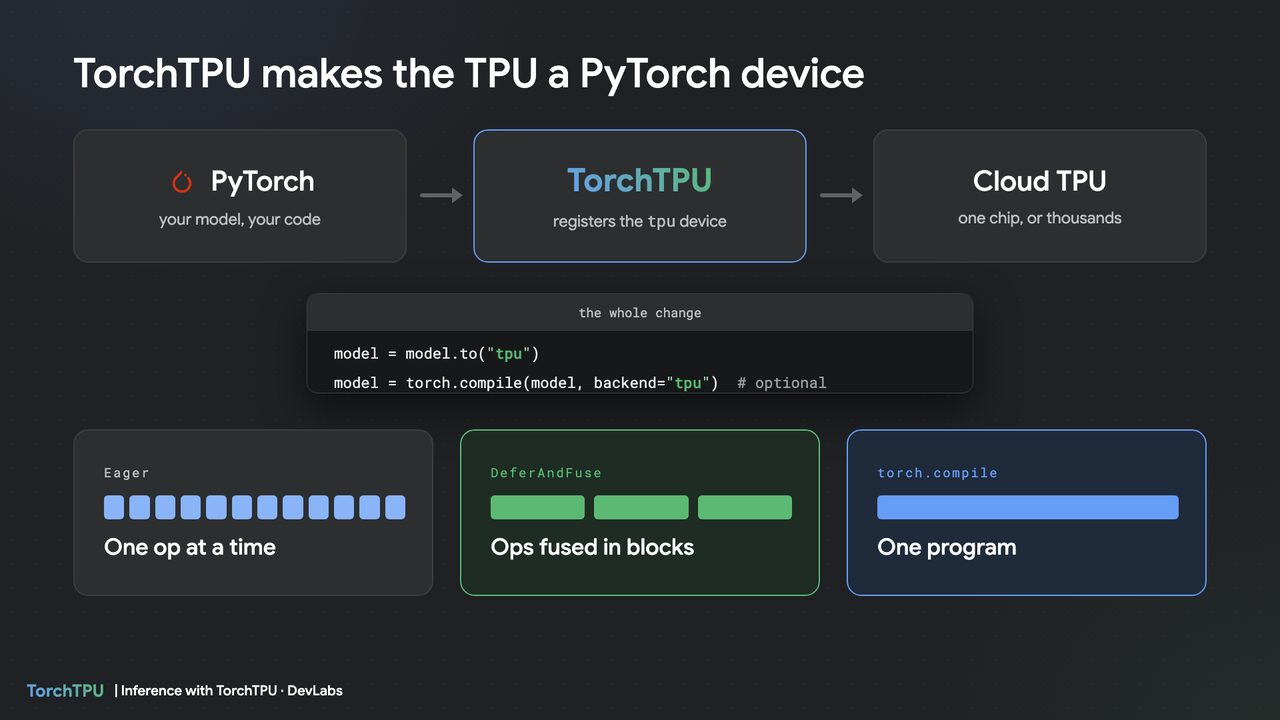

> **Where this was tested.** On a Cloud TPU v6e-1 (one Trillium chip, 32 GB HBM), run top to
> bottom with `jupyter nbconvert --execute`, from a Python 3.13 kernel like Colab's (Nov 8).
> Colab's TPU runtime is a different chip, so timings and memory differ; the shape of what
> you see does not.

Sources: the TorchTPU README and docs (`github.com/google-pytorch/torch_tpu`: "Install via
pip", "Optimized eager mode" in the execution-model page, "Performance profiling with
XProf").

## 1. Install

What you are looking at: TorchTPU is a pip package, `torch_tpu`, installed next to a CPU
build of PyTorch (the README's install line). The cell is idempotent: if `torch_tpu`
already imports, nothing is installed. It prints the versions either way. In Colab the
install takes about a minute.

In [ ]:
import importlib.util, importlib.metadata as md

if importlib.util.find_spec("torch_tpu") is None:
    %pip install -q torch_tpu==0.2.0 --extra-index-url https://download.pytorch.org/whl/cpu

for p in ["torch", "torch_tpu", "libtpu"]:
    print(f"{p:10s} {md.version(p)}")

## 2. The device line

What you are looking at: `import torch` is enough. TorchTPU registers `tpu` as a PyTorch
device when PyTorch loads, so there is no TorchTPU import in the live demo's scripts and
none here. `torch.accelerator.current_accelerator()` returns it, so code that asks PyTorch
for the current accelerator needs no change at all. A tensor made with `device="tpu"`
lives in the chip's HBM.

In [ ]:
import torch

device = torch.accelerator.current_accelerator()
print("current accelerator:", device)

x = torch.randn(4, 4, device="tpu")
print(x.device, x.dtype, tuple(x.shape))

## 3. Eager mode

What you are looking at: `demos/01_one_chip/example1_eager.py` from the live demo, a
12-block MLP run op by op, the way PyTorch runs anywhere. Each op is dispatched to the
chip as it is reached; `torch.accelerator.synchronize()` waits for the chip before the
clock is read, so the time printed is the whole step. The first step includes one-time
work; the later lines are the steady state. This is the mode to debug in: print a tensor,
set a breakpoint, it behaves like normal PyTorch.

In [ ]:
import time
from torch import nn

model = nn.Sequential(*[
    nn.Sequential(nn.LayerNorm(1024),
                  nn.Linear(1024, 4096), nn.GELU(),
                  nn.Linear(4096, 1024))
    for _ in range(12)
]).to(device)
x = torch.randn(16, 512, 1024, device=device)

with torch.no_grad():
    for i in range(1, 301):
        t0 = time.perf_counter()
        y = model(x)
        torch.accelerator.synchronize()  # wait
        ms = (time.perf_counter() - t0) * 1000
        if i == 1 or i % 100 == 0:
            print(f"eager step {i}: {ms:.1f} ms")

print(y.device, tuple(y.shape))

## 4. DeferAndFuse, the optimized eager mode

What you are looking at: the same model, still eager, with TorchTPU holding the ops back
and running them as fused blocks, up to the point where a value is needed (a `.cpu()`, an
`.item()`, a synchronize). Fewer, bigger programs on the chip; still eager, so a print or
a breakpoint still works. In the live demo this was the same file run again with
`TORCH_TPU_DEFER_AND_FUSE=1` in front of the command, not a character changed. In a
notebook, where `torch` is already imported, the same switch is the context manager
`torch.tpu.set_eager_mode(torch.tpu.EagerMode.DEFER_AND_FUSE)` (TorchTPU docs, "Optimized
eager mode"). The loop is the one above, as a function from here on. The first step
compiles the fused blocks; the later lines are the steady state.

In [ ]:
def steps(fn, label, n=300):
    with torch.no_grad():
        for i in range(1, n + 1):
            t0 = time.perf_counter()
            y = fn(x)
            torch.accelerator.synchronize()  # wait
            ms = (time.perf_counter() - t0) * 1000
            if i == 1 or i % 100 == 0:
                print(f"{label} step {i}: {ms:.1f} ms")
    return y


with torch.tpu.set_eager_mode(torch.tpu.EagerMode.DEFER_AND_FUSE):
    y = steps(model, "defer")
print(y.device, tuple(y.shape))

## 5. `torch.compile`

What you are looking at: the same model with one more line, `torch.compile(model,
backend="tpu")`. The first step is the compile: Dynamo captures the whole forward as a
graph and TorchTPU compiles it into one program for the TPU, which is why that step takes
much longer. Every step after it runs the compiled program. The mode to ship. Compare the
steady-state lines of the three runs on your own machine; this notebook makes no claim
about the ratios.

In [ ]:
compiled = torch.compile(model, backend="tpu")

y = steps(compiled, "compiled")
print(y.device, tuple(y.shape))

## 6. The three runs under the profiler

What you are looking at: the standard `torch.profiler`, with `ProfilerActivity.TPU` added
so the chip's side is recorded, tracing five steps of each run (all three are warm by
now). `TpuProfilerConfig` only names the folder for the device trace (`run_dir`); the
tracer levels are the documented defaults. Each capture goes to its own folder in
TensorBoard's layout, `traces/eager`, `traces/defer`, `traces/compiled`; `prof.step()`
marks each step in the trace. The `.pt.trace.json` is the Chrome trace the next cell
reads; the `.xplane.pb` is the device trace TensorBoard's profile plugin reads. The
live demo's `demos/01_one_chip/profiler.py` is this cell as a script:
`python profiler.py eager | defer | compiled`.

In [ ]:
import os
from torch.profiler import ProfilerActivity, profile, tensorboard_trace_handler
from torch.tpu.profiler import TpuProfilerConfig


def capture(name, fn, n=5):
    """n steps of fn(x) under the profiler, written to traces/<name>."""
    trace_dir = os.path.abspath(f"traces/{name}")
    with torch.no_grad(), profile(
        activities=[ProfilerActivity.CPU, ProfilerActivity.TPU],
        experimental_config=TpuProfilerConfig(run_dir=trace_dir),
        schedule=torch.profiler.schedule(wait=0, warmup=0, active=n, repeat=1),
        on_trace_ready=tensorboard_trace_handler(trace_dir),
    ) as prof:
        for i in range(1, n + 1):
            t0 = time.perf_counter()
            y = fn(x)
            torch.accelerator.synchronize()  # wait
            print(f"{name} step {i}: {(time.perf_counter() - t0) * 1000:.1f} ms")
            prof.step()  # marks the step in the trace (ProfilerStep#n)
    for root, _, files in os.walk(trace_dir):
        for f in sorted(files):
            p = os.path.join(root, f)
            print(f"  {os.path.relpath(p, 'traces')} ({os.path.getsize(p) / 1024:.0f} KB)")
    return trace_dir


eager_dir = capture("eager", model)
with torch.tpu.set_eager_mode(torch.tpu.EagerMode.DEFER_AND_FUSE):
    defer_dir = capture("defer", model)
compiled_dir = capture("compiled", compiled)

## 7. The three steps on one axis

What you are looking at: the same step from each capture, drawn from the Chrome trace on
one time axis. Every bar is one program the TPU ran (the trace viewer's *XLA Modules*
row). Eager is a comb: one program per op, with the host dispatching between them.
DeferAndFuse is fewer, bigger programs: the ops of a block fused into one. Compiled is
one program, all the ops fused inside it. The count and the step time are printed next to
each row; they are this chip's, and this notebook makes no claim about the ratios.
Programs shorter than a pixel are drawn one pixel wide.

In [ ]:
import glob
import json

if importlib.util.find_spec("matplotlib") is None:
    %pip install -q matplotlib
import matplotlib.pyplot as plt


def tpu_programs(trace_dir, step_index=2):
    """The TPU programs of one step: [(start_ms, dur_ms, name)], and the step's length in ms."""
    path = max(glob.glob(f"{trace_dir}/*.pt.trace.json"), key=os.path.getmtime)
    with open(path) as f:
        events = json.load(f)["traceEvents"]
    threads = {(e["pid"], e["tid"]): e["args"]["name"]
               for e in events if e.get("ph") == "M" and e["name"] == "thread_name"}
    programs = [e for e in events if e.get("ph") == "X"
                and threads.get((e["pid"], e["tid"])) == "XLA Modules"]
    steps = sorted((e for e in events if e.get("ph") == "X"
                    and e["name"].startswith("ProfilerStep#")), key=lambda e: e["ts"])
    if steps:  # one steady step; the profiler marks each prof.step()
        s = steps[min(step_index, len(steps) - 1)]
        t0, t1 = s["ts"], s["ts"] + s["dur"]
    else:
        t0 = min(e["ts"] for e in programs)
        t1 = max(e["ts"] + e["dur"] for e in programs)
    inside = sorted((e for e in programs if t0 <= e["ts"] <= t1), key=lambda e: e["ts"])
    return [((e["ts"] - t0) / 1000, e["dur"] / 1000, e["name"]) for e in inside], (t1 - t0) / 1000


rows = [("eager", "#4285F4", *tpu_programs(eager_dir)),
        ("DeferAndFuse", "#F9AB00", *tpu_programs(defer_dir)),
        ("compiled", "#34A853", *tpu_programs(compiled_dir))]
width = max(step_ms for _, _, _, step_ms in rows)

for label, _, bars, step_ms in rows:
    print(f"{label:13s} {len(bars)} program{'s' if len(bars) != 1 else ''} on the TPU in one step of {step_ms:.1f} ms")

fig, ax = plt.subplots(figsize=(14, 3.6))
for y, (label, color, bars, step_ms) in enumerate(reversed(rows)):
    ax.broken_barh([(s, max(d, width / 1400)) for s, d, _ in bars], (y + 0.15, 0.7),
                   facecolor=color, edgecolor="white", linewidth=0.8)
    n = f"{len(bars)} program{'s' if len(bars) != 1 else ''}"
    ax.text(width * 1.01, y + 0.5, f"{n}, {step_ms:.1f} ms", va="center")
ax.set_xlim(0, width)
ax.set_yticks([0.5, 1.5, 2.5], [r[0] for r in reversed(rows)])
ax.set_xlabel("ms from the start of the step (same scale for all three)")
ax.set_title("What the TPU ran in one step: one op at a time, fused blocks, or one program")
plt.tight_layout()
plt.show()

### What the session showed

The same three runs on the Cloud TPU v6e-1 of the live demo, in TensorBoard's trace
viewer, one true scale (100 px per ms), each frame starting at its step 2: eager's one
step fills the frame, DeferAndFuse fits three steps, compiled four. The *XLA Modules* row
is what the figure above draws.

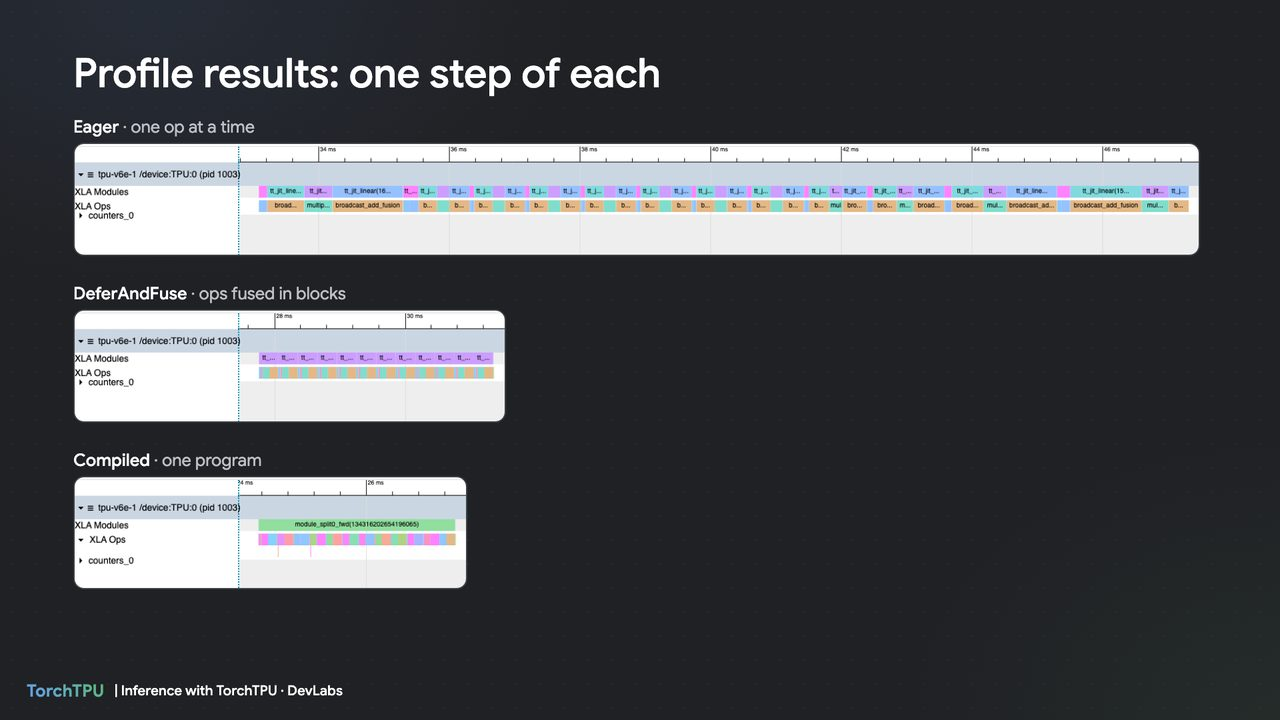

### The full trace viewer

The TorchTPU docs ("Performance profiling with XProf") view the captures in TensorBoard
with the profile plugin. In Colab, or any Jupyter:

```
%pip install "setuptools<81" xprof tensorboard
%load_ext tensorboard
%tensorboard --logdir traces
```

then open the **Profile** tab and pick the **trace_viewer** tool. The **Runs** list has
`eager`, `defer` and `compiled`; switch between them. On a VM, run `tensorboard --logdir
traces --port 6006` and open `http://localhost:6006` through an ssh tunnel (`ssh -L
6006:localhost:6006 ...`). The trace viewer shows one row per device stream and one per
host thread, with the ops inside each program on the *XLA Ops* row; over the timeline,
`w`/`s` zoom at the mouse and `a`/`d` pan. (XProf 2.24.0's side menu can draw over the
page; the trace viewer tool itself is fine. A wider window helps.)

## Where to go next

- The TorchTPU docs' own introductory notebook, which goes further into the device,
  the execution model and `torch.compile`:
  [intro_to_torchtpu.ipynb in Colab](https://colab.research.google.com/github/google-pytorch/torch_tpu/blob/0.2.0-docs/docs/notebooks/intro_to_torchtpu.ipynb).
- `github.com/google-pytorch/torch_tpu`: the README, the execution-model page (the three
  modes) and "Performance profiling with XProf" under `docs/`.
- The next two notebooks in this folder serve a model on the same chip with SGLang and
  with vLLM.
- Extra, not part of the session: `demos/04_kernel/` in this repository writes one op
  (RMSNorm) as a Pallas kernel called from PyTorch (TorchTPU docs, "Custom kernels").